In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV, ElasticNet, ElasticNetCV, LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score, confusion_matrix, classification_report, roc_auc_score, roc_curve, accuracy_score, average_precision_score, silhouette_score, precision_score, recall_score, f1_score
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

from scipy.cluster.hierarchy import linkage, dendrogram

from geopy.distance import geodesic

In [2]:
df = pd.read_csv(r"C:\Users\marti\OneDrive\Boston University Classes\DX799 - DS Capstone - Fall 2026\Datasets for capstone\Loan_approval_data_2025.csv", sep=",")
df

,customer_id,age,occupation_status,years_employed,annual_income,credit_score,credit_history_years,savings_assets,current_debt,defaults_on_file,delinquencies_last_2yrs,derogatory_marks,product_type,loan_intent,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,loan_status
0,CUST100000,40,Employed,17.2,25579,692,5.3,895,10820,0,0,0,Credit Card,Business,600,17.02,0.423,0.023,0.008,1
1,CUST100001,33,Employed,7.3,43087,627,3.5,169,16550,0,1,0,Personal Loan,Home Improvement,53300,14.10,0.384,1.237,0.412,0
2,CUST100002,42,Student,1.1,20840,689,8.4,17,7852,0,0,0,Credit Card,Debt Consolidation,2100,18.33,0.377,0.101,0.034,1
3,CUST100003,53,Student,0.5,29147,692,9.8,1480,11603,0,1,0,Credit Card,Business,2900,18.74,0.398,0.099,0.033,1
4,CUST100004,32,Employed,12.5,63657,630,7.2,209,12424,0,0,0,Personal Loan,Education,99600,13.92,0.195,1.565,0.522,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,CUST149995,35,Employed,4.3,39449,570,16.3,1127,7576,0,0,0,Credit Card,Education,42800,21.31,0.192,1.085,0.362,0
49996,CUST149996,34,Employed,4.4,20496,672,12.6,1478,6276,1,0,0,Credit Card,Personal,3800,18.07,0.306,0.185,0.062,0
49997,CUST149997,41,Self-Employed,4.8,18743,719,10.1,17,10331,0,0,0,Credit Card,Personal,18000,17.45,0.551,0.960,0.320,0
49998,CUST149998,38,Student,0.4,17250,633,1.3,5,7779,0,0,1,Personal Loan,Personal,1400,14.71,0.451,0.081,0.027,0


#### Regression — Predict loan_amount
#### Classification — Predict loan_status

### EDA

In [3]:
df.describe()

,age,years_employed,annual_income,credit_score,credit_history_years,savings_assets,current_debt,defaults_on_file,delinquencies_last_2yrs,derogatory_marks,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,loan_status
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,34.957060,7.454868,50062.892040,643.614820,8.168274,3595.619400,14290.442220,0.053480,0.55464,0.147640,33041.874000,15.498591,0.285724,0.701999,0.233995,0.550460
std,11.118603,7.612097,32630.501014,64.731518,7.207552,13232.399398,13243.757493,0.224991,0.84505,0.412996,26116.185102,4.067942,0.159787,0.465788,0.155268,0.497452
min,18.000000,0.000000,15000.000000,348.000000,0.000000,0.000000,60.000000,0.000000,0.00000,0.000000,500.000000,6.000000,0.002000,0.008000,0.003000,0.000000
25%,26.000000,1.300000,27280.500000,600.000000,2.000000,130.000000,5581.000000,0.000000,0.00000,0.000000,12300.000000,12.180000,0.161000,0.333000,0.111000,0.000000
50%,35.000000,4.900000,41607.500000,643.000000,6.100000,568.000000,10385.000000,0.000000,0.00000,0.000000,26100.000000,15.440000,0.265000,0.622000,0.207000,1.000000
75%,43.000000,11.400000,62723.250000,687.000000,12.600000,2271.000000,18449.250000,0.000000,1.00000,0.000000,48500.000000,18.870000,0.389000,1.010250,0.337000,1.000000
max,70.000000,39.900000,250000.000000,850.000000,30.000000,300000.000000,163344.000000,1.000000,9.00000,4.000000,100000.000000,23.000000,0.800000,2.001000,0.667000,1.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              50000 non-null  object 
 1   age                      50000 non-null  int64  
 2   occupation_status        50000 non-null  object 
 3   years_employed           50000 non-null  float64
 4   annual_income            50000 non-null  int64  
 5   credit_score             50000 non-null  int64  
 6   credit_history_years     50000 non-null  float64
 7   savings_assets           50000 non-null  int64  
 8   current_debt             50000 non-null  int64  
 9   defaults_on_file         50000 non-null  int64  
 10  delinquencies_last_2yrs  50000 non-null  int64  
 11  derogatory_marks         50000 non-null  int64  
 12  product_type             50000 non-null  object 
 13  loan_intent              50000 non-null  object 
 14  loan_amount           

In [5]:
df.isnull().sum().sort_values(ascending=False)

customer_id                0
age                        0
payment_to_income_ratio    0
loan_to_income_ratio       0
debt_to_income_ratio       0
interest_rate              0
loan_amount                0
loan_intent                0
product_type               0
derogatory_marks           0
delinquencies_last_2yrs    0
defaults_on_file           0
current_debt               0
savings_assets             0
credit_history_years       0
credit_score               0
annual_income              0
years_employed             0
occupation_status          0
loan_status                0
dtype: int64

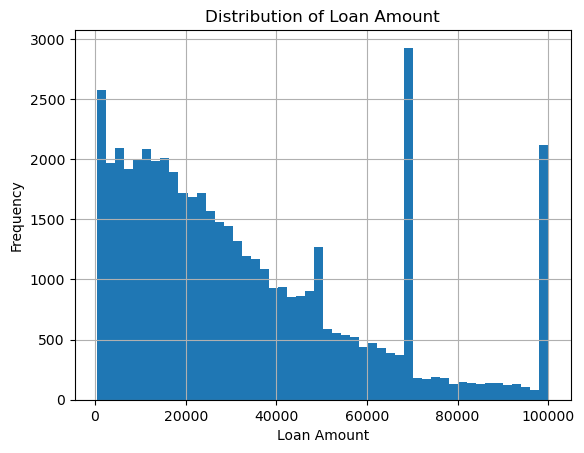

In [6]:
df["loan_amount"].hist(bins = 50)
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.title("Distribution of Loan Amount")
plt.show()

In [7]:
# Check for imbalance
df["loan_status"].value_counts(normalize=True) 

loan_status
1    0.55046
0    0.44954
Name: proportion, dtype: float64

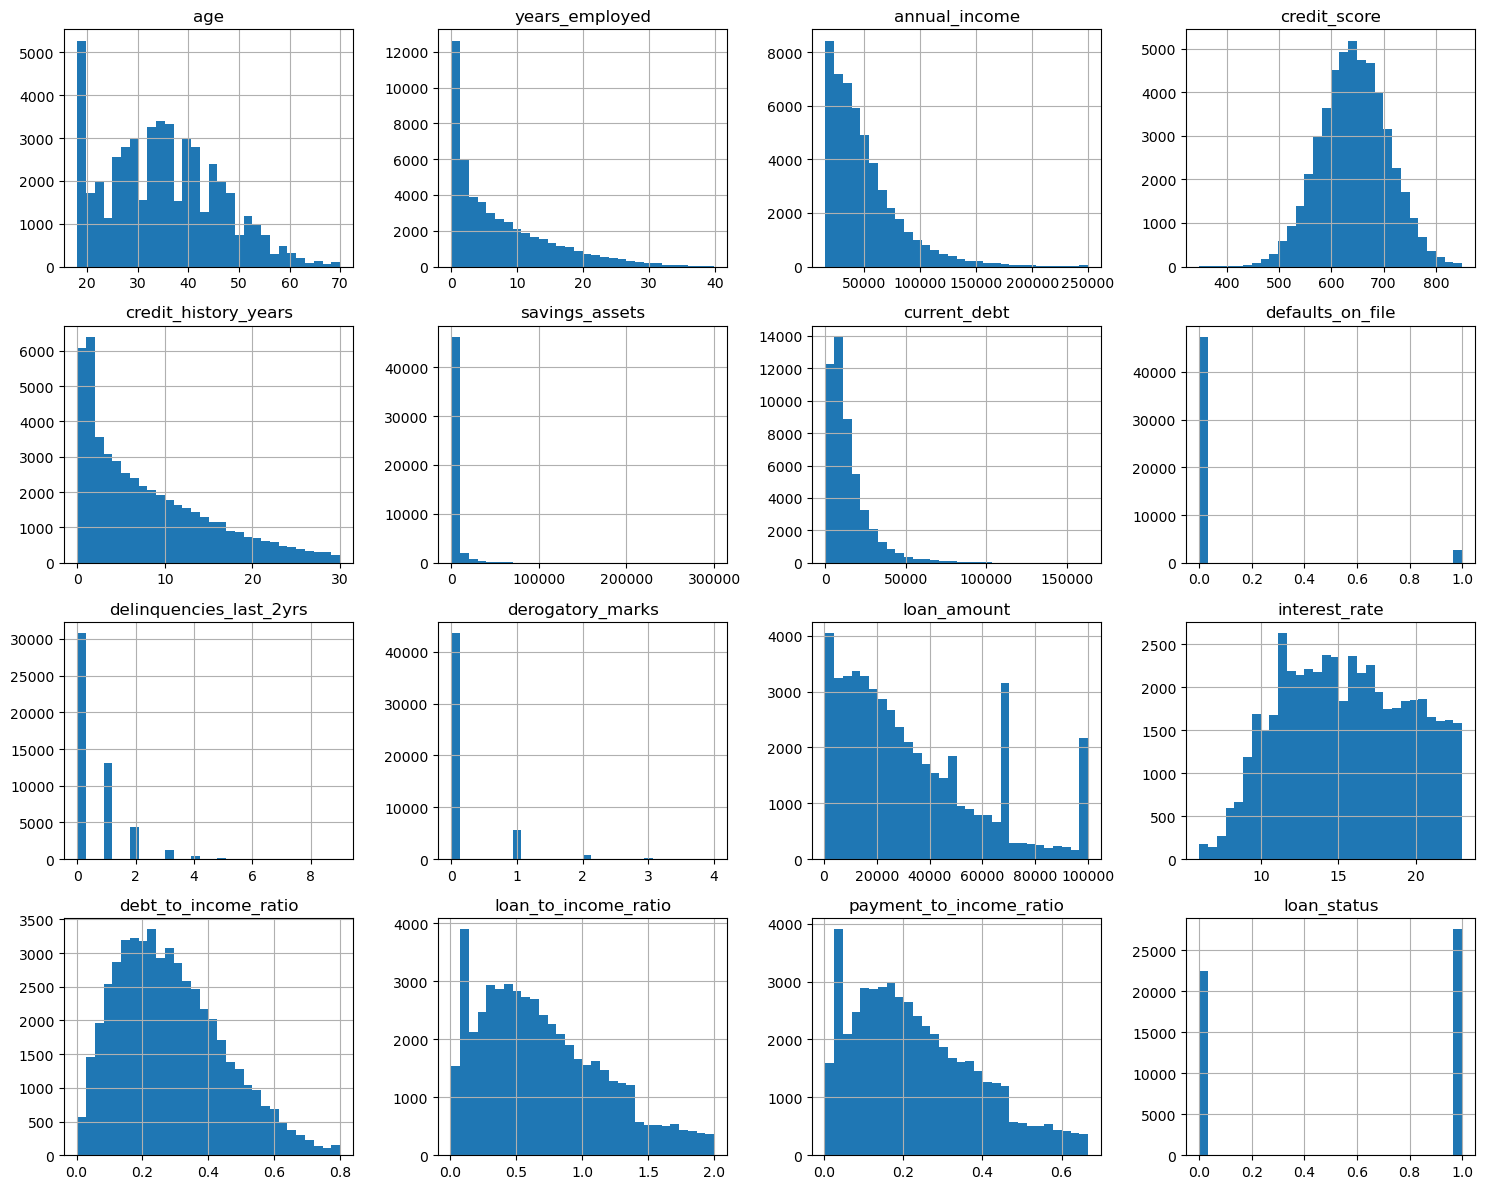

In [8]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
df[num_cols].hist(figsize = (15, 12), bins = 30)
plt.tight_layout()
plt.show()

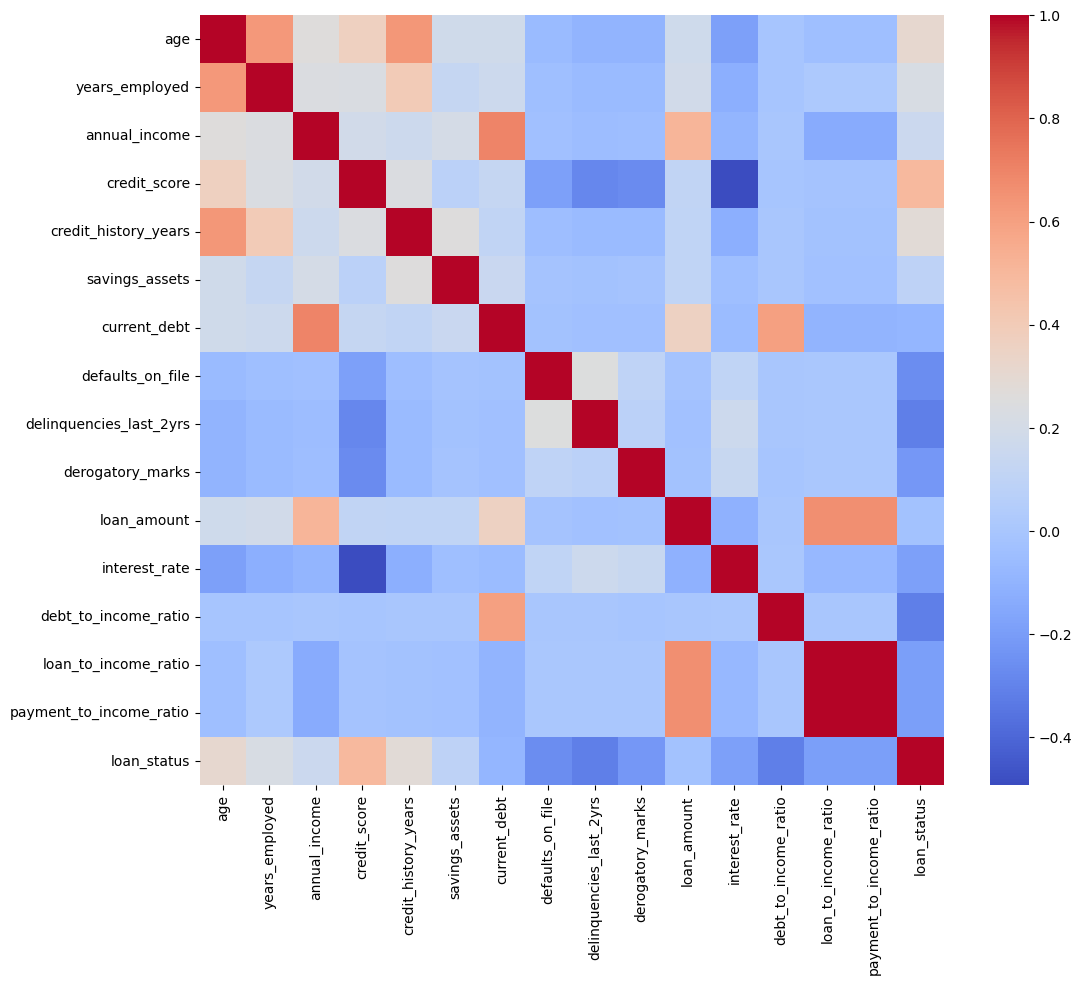

In [9]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True),
            cmap = "coolwarm")
plt.show()

In [10]:
df.corr(numeric_only=True)["loan_amount"].sort_values(ascending=False)

loan_amount                1.000000
payment_to_income_ratio    0.662176
loan_to_income_ratio       0.662174
annual_income              0.511129
current_debt               0.359800
years_employed             0.185206
age                        0.172352
credit_score               0.112019
credit_history_years       0.107280
savings_assets             0.106962
debt_to_income_ratio      -0.001320
defaults_on_file          -0.019340
derogatory_marks          -0.024051
loan_status               -0.025987
delinquencies_last_2yrs   -0.029398
interest_rate             -0.110787
Name: loan_amount, dtype: float64

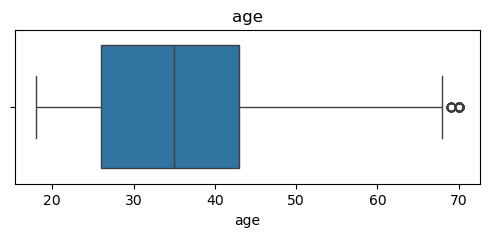

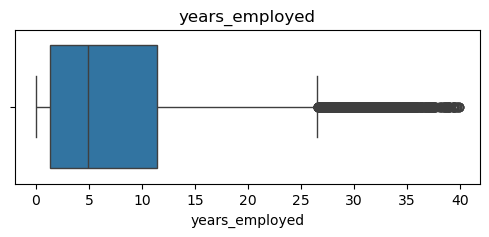

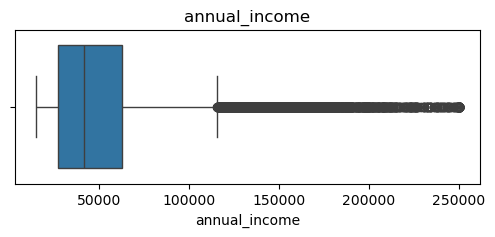

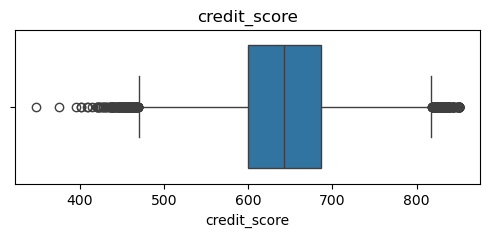

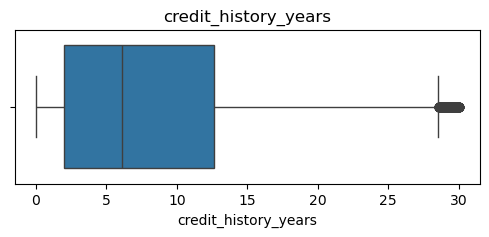

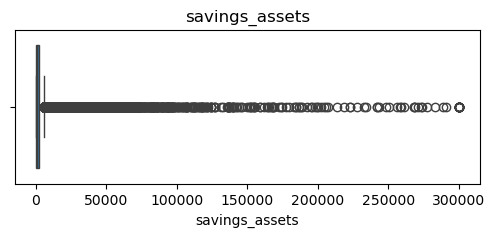

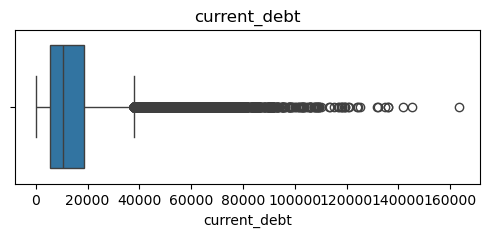

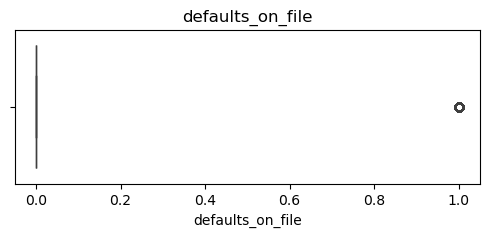

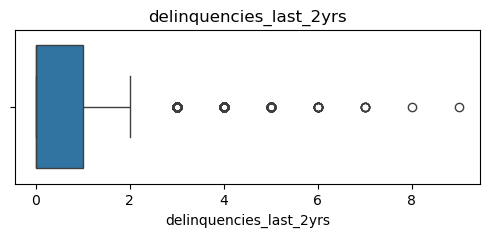

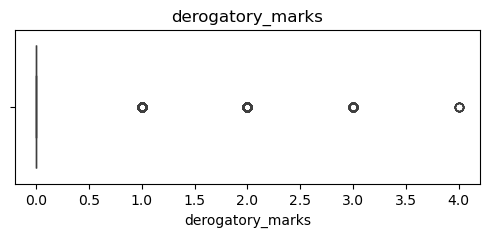

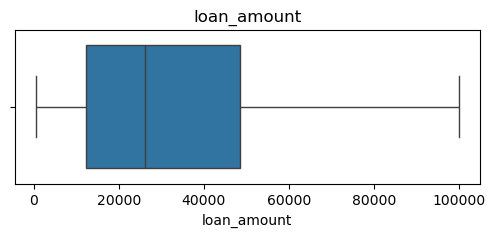

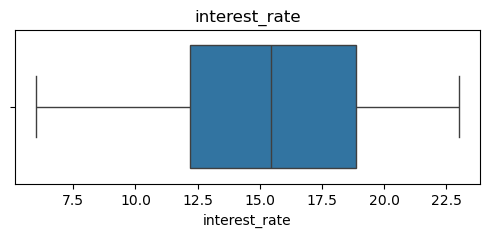

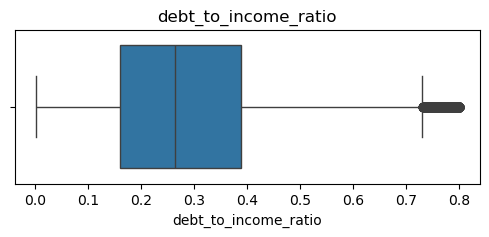

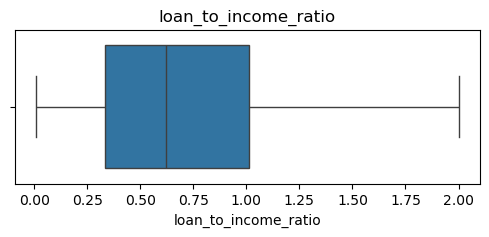

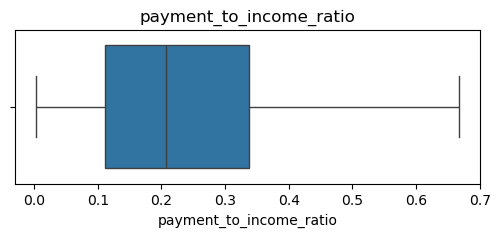

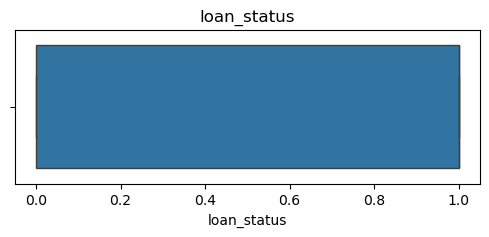

In [11]:
for col in num_cols:
    plt.figure(figsize=(6, 2))
    sns.boxplot(x = df[col])
    plt.title(col)
    plt.show()

## Week 8: K-Nearest Neighbors

In [12]:
## Feature Engineering ##

# Polynomial Terms
df["credit_score_sq"] = df["credit_score"] ** 2
df["annual_income_sq"] = df["annual_income"] ** 2
df["years_employed_sq"] = df["years_employed"] ** 2

# Interaction Terms
#df["dti_interact"] = (df["debt_to_income_ratio"] * df["annual_income"])
df["credit_income_interact"] = (df["credit_score"] * df["annual_income"])
df["employed_income_interact"] = (df["years_employed"] * df["annual_income"])

X = df.drop(columns=["customer_id", "loan_status"])
y = df["loan_status"]

X = pd.get_dummies(
    X,
    columns = ["occupation_status", "product_type", "loan_intent"],
    drop_first = True,
    dtype = int
)

print(X.shape)
print(X.dtypes)

(50000, 29)
age                                  int64
years_employed                     float64
annual_income                        int64
credit_score                         int64
credit_history_years               float64
savings_assets                       int64
current_debt                         int64
defaults_on_file                     int64
delinquencies_last_2yrs              int64
derogatory_marks                     int64
loan_amount                          int64
interest_rate                      float64
debt_to_income_ratio               float64
loan_to_income_ratio               float64
payment_to_income_ratio            float64
credit_score_sq                      int64
annual_income_sq                     int64
years_employed_sq                  float64
credit_income_interact               int64
employed_income_interact           float64
occupation_status_Self-Employed      int32
occupation_status_Student            int32
product_type_Line of Credit          int32

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (40000, 29)
Testing: (10000, 29)


In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Scaled:", X_train_scaled.shape)
print("Testing Scaled:", X_test_scaled.shape)

Training Scaled: (40000, 29)
Testing Scaled: (10000, 29)


#### Build KNN Model

In [15]:
euclidean_knn = KNeighborsClassifier(
    n_neighbors = 5,
    metric = "euclidean"
)

# train model
euclidean_knn.fit(X_train_scaled, y_train)

y_pred_euclidean = euclidean_knn.predict(X_test_scaled)

# performance
print("KNN - Euclidean Distance (K = 5)")
print("Accuracy:", accuracy_score(y_test, y_pred_euclidean))
print("\nClassification Report:\n", classification_report(y_test, y_pred_euclidean))

  File "c:\Users\marti\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\marti\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\marti\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\marti\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


KNN - Euclidean Distance (K = 5)
Accuracy: 0.8651

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.80      0.84      4495
           1       0.85      0.92      0.88      5505

    accuracy                           0.87     10000
   macro avg       0.87      0.86      0.86     10000
weighted avg       0.87      0.87      0.86     10000



In [16]:
manhattan_knn = KNeighborsClassifier(
    n_neighbors = 5,
    metric = "manhattan"
)

# train model
manhattan_knn.fit(X_train_scaled, y_train)

y_pred_manhattan = manhattan_knn.predict(X_test_scaled)

# performance
print("KNN - Manhattan Distance (K = 5)")
print("Accuracy:", accuracy_score(y_test, y_pred_manhattan))
print("\nClassification Report:\n", classification_report(y_test, y_pred_manhattan))

KNN - Manhattan Distance (K = 5)
Accuracy: 0.857

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.78      0.83      4495
           1       0.84      0.92      0.88      5505

    accuracy                           0.86     10000
   macro avg       0.86      0.85      0.85     10000
weighted avg       0.86      0.86      0.86     10000



In [17]:
cosine_knn = KNeighborsClassifier(
    n_neighbors = 5,
    metric = "cosine"
)

# train model
cosine_knn.fit(X_train_scaled, y_train)

y_pred_cosine = cosine_knn.predict(X_test_scaled)

# performance
print("KNN - Cosine Distance (K = 5)")
print("Accuracy:", accuracy_score(y_test, y_pred_cosine))
print("\nClassification Report:\n", classification_report(y_test, y_pred_cosine))

KNN - Cosine Distance (K = 5)
Accuracy: 0.8663

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.83      0.85      4495
           1       0.86      0.90      0.88      5505

    accuracy                           0.87     10000
   macro avg       0.87      0.86      0.86     10000
weighted avg       0.87      0.87      0.87     10000



In [18]:
minkowski_knn = KNeighborsClassifier(
    n_neighbors = 5,
    metric = "minkowski"
)

# train model
minkowski_knn.fit(X_train_scaled, y_train)

y_pred_minkowski = minkowski_knn.predict(X_test_scaled)

# performance
print("KNN - Minkowski Distance (K = 5)")
print("Accuracy:", accuracy_score(y_test, y_pred_minkowski))
print("\nClassification Report:\n", classification_report(y_test, y_pred_minkowski))

KNN - Minkowski Distance (K = 5)
Accuracy: 0.8651

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.80      0.84      4495
           1       0.85      0.92      0.88      5505

    accuracy                           0.87     10000
   macro avg       0.87      0.86      0.86     10000
weighted avg       0.87      0.87      0.86     10000



In [19]:
def test_knn_model(X_train, y_train, k_values):
    metrics = {
        "Euclidean": {"metric": "euclidean"},
        "Manhattan": {"metric": "manhattan"},
        "Cosine": {"metric": "cosine"},
        "Minkowski": {"metric": "minkowski", "p": 3}
    }

    results = []

    cv = StratifiedKFold(
        n_splits = 3,
        shuffle = True,
        random_state = 42
    )

    for metric_name, params in metrics.items():
        for k in k_values:
            
            model = Pipeline([
                ("scaler", StandardScaler()),
                ("knn", KNeighborsClassifier(
                    n_neighbors = k,
                    **params
                ))
            ])

            scores = cross_val_score(
                model,
                X_train,
                y_train,
                cv = cv,
                scoring = "accuracy",
                n_jobs = -1
            )

            results.append({
                "Metric": metric_name,
                "K": k,
                "CV Accuracy": scores.mean(),
                "CV Std": scores.std()
            })

            print(f"{metric_name} | K = {k} | Accuracy = {scores.mean():.4f}")

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by = "CV Accuracy",
        ascending = False
    ).reset_index(drop = True)
    
    return results_df

In [20]:
k_values = [2, 3, 4, 5, 7, 9, 11, 15, 21]

knn_results = test_knn_model(
    X_train,
    y_train,
    k_values
)

print(knn_results)

Euclidean | K = 2 | Accuracy = 0.8268
Euclidean | K = 3 | Accuracy = 0.8489
Euclidean | K = 4 | Accuracy = 0.8519
Euclidean | K = 5 | Accuracy = 0.8557
Euclidean | K = 7 | Accuracy = 0.8606
Euclidean | K = 9 | Accuracy = 0.8621
Euclidean | K = 11 | Accuracy = 0.8606
Euclidean | K = 15 | Accuracy = 0.8606
Euclidean | K = 21 | Accuracy = 0.8606
Manhattan | K = 2 | Accuracy = 0.8237
Manhattan | K = 3 | Accuracy = 0.8447
Manhattan | K = 4 | Accuracy = 0.8504
Manhattan | K = 5 | Accuracy = 0.8524
Manhattan | K = 7 | Accuracy = 0.8550
Manhattan | K = 9 | Accuracy = 0.8577
Manhattan | K = 11 | Accuracy = 0.8585
Manhattan | K = 15 | Accuracy = 0.8581
Manhattan | K = 21 | Accuracy = 0.8563
Cosine | K = 2 | Accuracy = 0.8232
Cosine | K = 3 | Accuracy = 0.8504
Cosine | K = 4 | Accuracy = 0.8489
Cosine | K = 5 | Accuracy = 0.8570
Cosine | K = 7 | Accuracy = 0.8616
Cosine | K = 9 | Accuracy = 0.8626
Cosine | K = 11 | Accuracy = 0.8634
Cosine | K = 15 | Accuracy = 0.8656
Cosine | K = 21 | Accuracy =

In [21]:
best_per_metric = (
    knn_results
    .drop_duplicates(subset = "Metric")
    .reset_index(drop = True)
)
print(best_per_metric)

      Metric   K  CV Accuracy   CV Std
0     Cosine  15     0.865575  0.00187
1  Euclidean   9     0.862075  0.00142
2  Manhattan  11     0.858450  0.00141
3  Minkowski  11     0.858225  0.00126


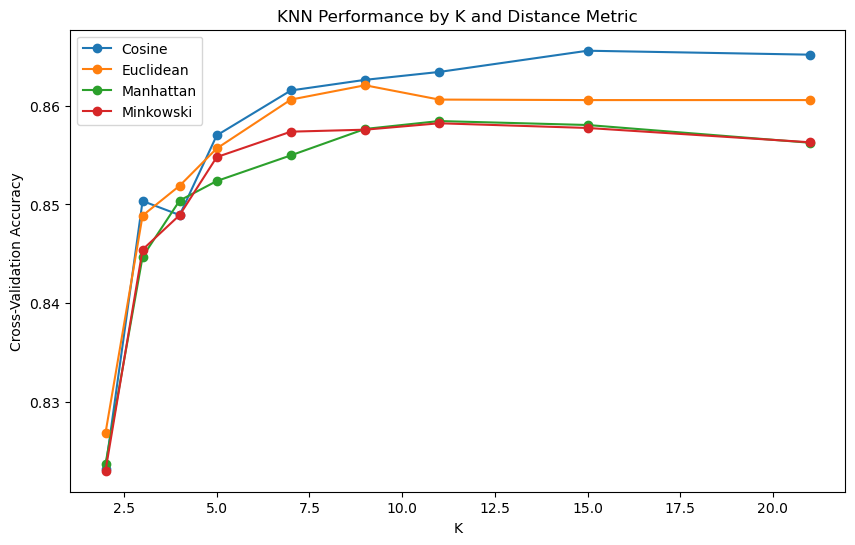

In [22]:
plt.figure(figsize = (10, 6))

for metric in knn_results["Metric"].unique():
    subset = knn_results[knn_results["Metric"] == metric].sort_values("K")
    plt.plot(subset["K"], subset["CV Accuracy"], marker = "o", label = metric)

plt.xlabel("K")
plt.ylabel("Cross-Validation Accuracy")
plt.title("KNN Performance by K and Distance Metric")
plt.legend()
plt.show()

The graph shows that the model performance general improved as K increased from 2 to moderate values, then begin to remain steady. Cosine distance produced teh strongest overall performance, reaching its highest corss-validation accuracy at K = 15. 

### Final KNN Evaluation on test data using the Optimal K - Cosine k=15

In [23]:
best_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors = 15,
        metric = "cosine"
    )
)

best_knn.fit(X_train, y_train)
y_pred_best = best_knn.predict(X_test)

print("Optimized KNN - Cosine (k=15)")
print("Accuracy:", accuracy_score(y_test, y_pred_best))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

Optimized KNN - Cosine (k=15)
Accuracy: 0.8717

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.82      0.85      4495
           1       0.86      0.92      0.89      5505

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000


Confusion Matrix:
[[3673  822]
 [ 461 5044]]


## Week 9 Gradient Boost

In [24]:
# Get baseline model

gb_base = GradientBoostingClassifier(random_state = 42)

gb_base.fit(X_train, y_train)

y_pred = gb_base.predict(X_test)
y_prob = gb_base.predict_proba(X_test)[:, 1]


print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print(f"\nRoc-AUC: {roc_auc_score(y_test, y_prob):.4f}")

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.89      0.91      4495
           1       0.91      0.94      0.93      5505

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000


Confusion Matrix:
[[3998  497]
 [ 316 5189]]

Roc-AUC: 0.9793


#### Test learning Rate

In [25]:
learning_rates = [0.01, 0.05, 0.1, 0.2]
lr_results = []

cv = StratifiedKFold(
    n_splits = 3,
    shuffle = True,
    random_state = 42
)

for lr in learning_rates:
    gb_model = GradientBoostingClassifier(
        learning_rate = lr,
        n_estimators = 100,
        max_depth = 3,
        random_state = 42
    )

    scores = cross_val_score(
        gb_model,
        X_train,
        y_train,
        cv = cv,
        scoring = "roc_auc",
        n_jobs = -1
    )

    lr_results.append({
        "Learning Rate": lr,
        "Mean ROC AUC": scores.mean(),
        "Std ROC AUC": scores.std()
    })

lr_results_df = pd.DataFrame(lr_results)

display(lr_results_df.round(4))

best_lr = lr_results_df.loc[
    lr_results_df["Mean ROC AUC"].idxmax(),
    "Learning Rate"
]

print(f"Best Learning Rate: {best_lr}")

,Learning Rate,Mean ROC AUC,Std ROC AUC
0,0.01,0.9212,0.0029
1,0.05,0.9707,0.0013
2,0.10,0.9794,0.0008
3,0.20,0.9833,0.0007


Best Learning Rate: 0.2


### Testing n_estimators

In [26]:
n_estimators_list = [50, 100, 150, 200, 300]
n_results = []

for n in n_estimators_list:
    gb_model = GradientBoostingClassifier(
        learning_rate = best_lr,
        n_estimators = n,
        max_depth = 3,
        random_state = 42
    )

    scores = cross_val_score(
        gb_model,
        X_train,
        y_train,
        cv = cv,
        scoring = "roc_auc",
        n_jobs = -1
    )

    n_results.append({
        "N Estimators": n,
        "Mean ROC AUC": scores.mean(),
        "Std ROC AUC": scores.std()
    })

n_results_df = pd.DataFrame(n_results)
display(n_results_df.round(4))

best_n = n_results_df.loc[
    n_results_df["Mean ROC AUC"].idxmax(),
    "N Estimators"]

print(f"Best Number of Estimators: {best_n}")

,N Estimators,Mean ROC AUC,Std ROC AUC
0,50,0.9792,0.0009
1,100,0.9833,0.0007
2,150,0.9843,0.0007
3,200,0.9847,0.0006
4,300,0.9847,0.0007


Best Number of Estimators: 300


### Tuning Depth

In [27]:
tree_depths = [1, 2, 3, 4, 5]
depth_results = []

for depth in tree_depths:
    gb_model = GradientBoostingClassifier(
        learning_rate = best_lr,
        n_estimators = best_n,
        max_depth = depth,
        random_state = 42
    )

    scores = cross_val_score(
        gb_model,
        X_train,
        y_train,
        cv = cv,
        scoring = "roc_auc",
        n_jobs = -1
    )

    depth_results.append({
        "Max Depth": depth,
        "Mean ROC AUC": scores.mean(),
        "Std ROC AUC": scores.std()
    })

depth_results_df = pd.DataFrame(depth_results)
display(depth_results_df.round(4))

best_depth = depth_results_df.loc[
    depth_results_df["Mean ROC AUC"].idxmax(),
    "Max Depth"]

print(f"Best Depth: {best_depth}")

,Max Depth,Mean ROC AUC,Std ROC AUC
0,1,0.9786,0.0011
1,2,0.9840,0.0006
2,3,0.9847,0.0007
3,4,0.9838,0.0006
4,5,0.9826,0.0006


Best Depth: 3


## Final Model

In [28]:
gb_final = GradientBoostingClassifier(
    learning_rate = best_lr,
    n_estimators = best_n,
    max_depth = best_depth,
    random_state = 42
)

gb_final.fit(X_train, y_train)

y_pred = gb_final.predict(X_test)
y_prob = gb_final.predict_proba(X_test)[:, 1]

# evaluate model
print("Final Gradient Boosting Model")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print(f"\nROC AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

Final Gradient Boosting Model

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.91      0.92      4495
           1       0.93      0.94      0.93      5505

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.91      0.92      4495
           1       0.93      0.94      0.93      5505

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000


Confusion Matrix:
[[4092  403]
 [ 327 5178]]

ROC AUC Score: 0.9848


## Week 10: Clustering 1

In [29]:
cluster_featues = ["age", "annual_income", "credit_score", "years_employed", "loan_amount", "interest_rate", "debt_to_income_ratio", "loan_to_income_ratio", "payment_to_income_ratio", "current_debt"]

X_cluster = df[cluster_featues].copy()
print("Data Shape:", X_cluster.shape)
print("\nMissing Values:")
print(X_cluster.isnull().sum())

display(X_cluster.head())

Data Shape: (50000, 10)

Missing Values:
age                        0
annual_income              0
credit_score               0
years_employed             0
loan_amount                0
interest_rate              0
debt_to_income_ratio       0
loan_to_income_ratio       0
payment_to_income_ratio    0
current_debt               0
dtype: int64


,age,annual_income,credit_score,years_employed,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,current_debt
0,40,25579,692,17.2,600,17.02,0.423,0.023,0.008,10820
1,33,43087,627,7.3,53300,14.10,0.384,1.237,0.412,16550
2,42,20840,689,1.1,2100,18.33,0.377,0.101,0.034,7852
3,53,29147,692,0.5,2900,18.74,0.398,0.099,0.033,11603
4,32,63657,630,12.5,99600,13.92,0.195,1.565,0.522,12424


In [30]:
## Feature Scaling

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)
X_scaled = pd.DataFrame(
    X_scaled,
    columns = X_cluster.columns,
    index = X_cluster.index
)

display(X_scaled.head())

,age,annual_income,credit_score,years_employed,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,current_debt
0,0.453563,-0.750345,0.747482,1.280229,-1.242226,0.374003,0.859129,-1.457758,-1.455529,-0.262046
1,-0.176018,-0.213787,-0.256675,-0.020345,0.775700,-0.343811,0.615051,1.148607,1.146448,0.170615
2,0.633444,-0.895579,0.701137,-0.834846,-1.184790,0.696037,0.571242,-1.290298,-1.288075,-0.486154
3,1.622787,-0.640998,0.747482,-0.913669,-1.154157,0.796826,0.702669,-1.294592,-1.294515,-0.202923
4,-0.265959,0.416612,-0.210330,0.662785,2.548565,-0.388060,-0.567789,1.852798,1.854907,-0.140931


### Elbow Method

,K,Inertia
0,2,406654.80
1,3,343076.02
2,4,308438.30
3,5,287461.06
4,6,269176.87
5,7,255796.49
6,8,245346.34
7,9,236430.85
8,10,228825.72


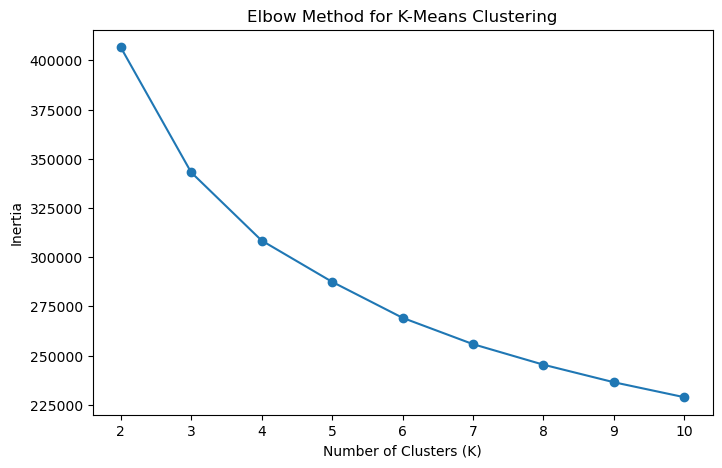

In [31]:
inertia = []

k_values = range(2, 11)
for k in k_values:
    kmeans = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

inertia_df = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia
})

display(inertia_df.round(2))

plt.figure(figsize = (8, 5))
plt.plot(k_values, inertia, marker = "o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(k_values)
plt.show()

### Silhouette Score

,K,Silhouette Score
0,2,0.1983
1,3,0.1970
2,4,0.1769
3,5,0.1535
4,6,0.1437
5,7,0.1424
6,8,0.1420
7,9,0.1415
8,10,0.1427


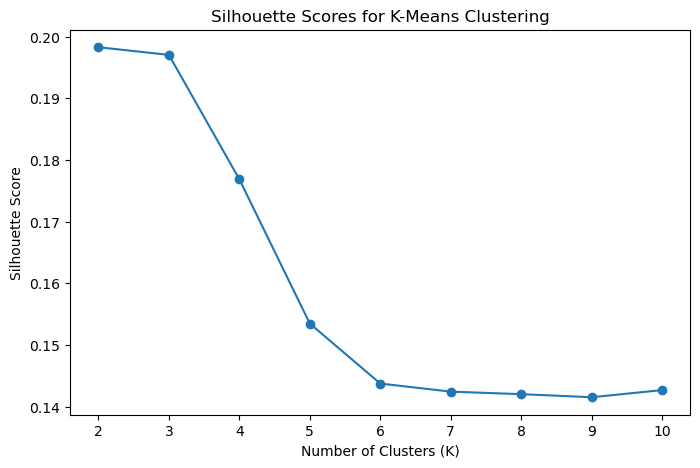

In [32]:
## Silhoutette

silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size = 5000,
        random_state = 42
    )

    silhouette_scores.append(score)

silhouette_df = pd.DataFrame({
    "K": list(k_values),
    "Silhouette Score": silhouette_scores
})
display(silhouette_df.round(4))

plt.figure(figsize = (8, 5))
plt.plot(k_values, silhouette_scores, marker = "o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores for K-Means Clustering")
plt.xticks(k_values)
plt.show()

#### Compare the two

In [33]:
results_df = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia,
    "Silhouette Score": silhouette_scores
})

display(results_df.round(4))

,K,Inertia,Silhouette Score
0,2,406654.7970,0.1983
1,3,343076.0204,0.1970
2,4,308438.3010,0.1769
3,5,287461.0552,0.1535
4,6,269176.8713,0.1437
5,7,255796.4947,0.1424
6,8,245346.3398,0.1420
7,9,236430.8494,0.1415
8,10,228825.7167,0.1427


### Compare k = 2 and k = 3

In [34]:
for k in [2, 3]:
    kmeans = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )

    labels = kmeans.fit_predict(X_scaled)
    cluster_counts = pd.Series(labels).value_counts().sort_index()

    print(f"\nK = {k}")
    print(f"Inertia: {kmeans.inertia_:.4f}")
    print("\nCluster Sizes:")
    print(cluster_counts)


K = 2
Inertia: 406654.7970

Cluster Sizes:
0    28791
1    21209
Name: count, dtype: int64

K = 3
Inertia: 343076.0204

Cluster Sizes:
0    23778
1    14928
2    11294
Name: count, dtype: int64


#### Examine borrower charasterics

In [35]:
for k in [2, 3]:
    kmeans = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )

    kmeans.fit(X_scaled)

    centroids = scaler.inverse_transform(kmeans.cluster_centers_)

    centroid_df = pd.DataFrame(
        centroids,
        columns = X_cluster.columns
    )

    centroid_df.index.name = "Cluster"

    print(f"\nK = {k} - Cluster Centroids")
    display(centroid_df.round(4))



K = 2 - Cluster Centroids


,age,annual_income,credit_score,years_employed,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,current_debt
Cluster,,,,,,,,,,
0,32.5250,39551.0706,632.9416,5.7543,15679.8448,15.8946,0.2741,0.4434,0.1478,10568.7357
1,38.2453,64275.4602,658.0456,9.7542,56516.3045,14.9631,0.3015,1.0516,0.3505,19322.3967



K = 3 - Cluster Centroids


,age,annual_income,credit_score,years_employed,loan_amount,interest_rate,debt_to_income_ratio,loan_to_income_ratio,payment_to_income_ratio,current_debt
Cluster,,,,,,,,,,
0,31.7542,36247.1924,630.2394,5.0274,14334.7808,15.9379,0.2671,0.4107,0.1369,9217.7128
1,33.2567,42859.4592,636.4184,6.6168,52593.5484,15.9071,0.2709,1.2704,0.4235,11157.6342
2,43.9728,88779.3151,681.3925,13.6905,46608.4657,14.0295,0.3446,0.5634,0.1878,29152.9481


### Fit Final Model

In [36]:
#############
# Fit model #
#############

best_k = 3

kmeans_final = KMeans(
    n_clusters = best_k,
    random_state = 42,
    n_init = 10
)

labels = kmeans_final.fit_predict(X_scaled)
df["Cluster"] = labels

######################
# Evaluate the model #
######################

final_inertia = kmeans_final.inertia_

final_silhouette = silhouette_score(
    X_scaled,
    labels,
    sample_size = 5000,
    random_state = 42
)

print(f"Final Number of Clusters: {best_k}")
print(f"Final Inertia: {final_inertia:.4f}")
print(f"Final Silhouette Score: {final_silhouette:.4f}")

Final Number of Clusters: 3
Final Inertia: 343076.0204
Final Silhouette Score: 0.1970


#### Loan Approval Rates by Cluster

In [37]:
cluster_summary = df.groupby("Cluster").agg(
    Borrowers = ("loan_status", "count"),
    Approved = ("loan_status", "sum"),
    Approval_Rate = ("loan_status", "mean"),
    Average_Income = ("annual_income", "mean"),
    Average_Credit_Score = ("credit_score", "mean"),
    Average_Loan_Amount = ("loan_amount", "mean")
)

cluster_summary["Approval_Rate"] = cluster_summary["Approval_Rate"] * 100

display(cluster_summary.round(4))

,Borrowers,Approved,Approval_Rate,Average_Income,Average_Credit_Score,Average_Loan_Amount
Cluster,,,,,,
0,23778,13274,55.8247,36231.5071,630.2121,14332.7403
1,14928,6445,43.1739,42855.4350,636.3975,52601.6546
2,11294,7804,69.0986,88709.5708,681.3720,46578.0326


Cluster 0 shows lower income and smaller loan borrowers.
Cluster 1 shows Higher loan amount
Cluster 2 shows Higher Income borrwers and higher approval rate

### Visualize with PCA

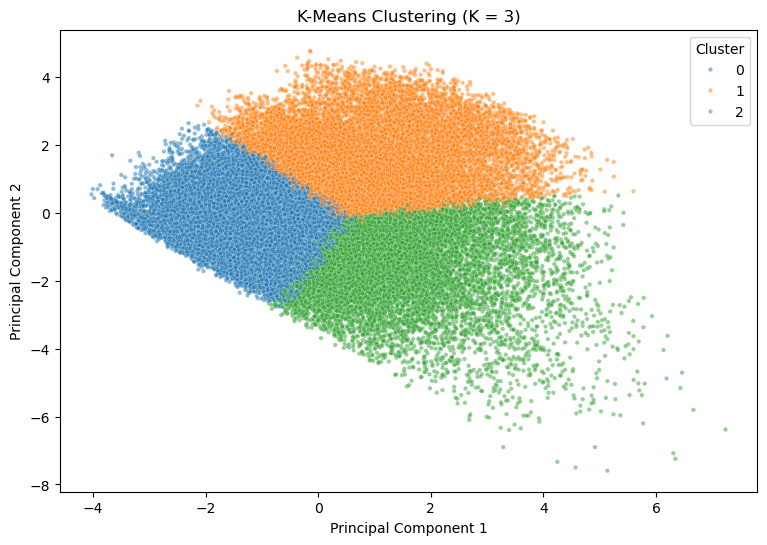

Explained Variance Ratio: [0.27622719 0.23995287]
Total Explained Variance: 0.5162


In [38]:
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize = (9, 6))

sns.scatterplot(
    x = X_pca[:, 0],
    y = X_pca[:, 1],
    hue = labels,
    palette = "tab10",
    alpha = 0.5,
    s = 10
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering (K = 3)")
plt.legend(title = "Cluster")
plt.show()

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print(f"Total Explained Variance: {pca.explained_variance_ratio_.sum():.4f}")

#### Compare Euclidean and Manhattan Distances

In [39]:
def calculate_distance(x1, x2):
    euclidean = np.sqrt(np.sum((x1 - x2) ** 2))
    manhattan = np.sum(np.abs(x1 - x2))

    return euclidean, manhattan

In [40]:
distance_results = []

for i in range(1, 10):

    euclidean, manhattan = calculate_distance(X_scaled.iloc[0], X_scaled.iloc[i])

    distance_results.append({
        "Borrower": i,
        "Euclidean Distance": euclidean,
        "Manhattan Distance": manhattan
    })

distance_df = pd.DataFrame(distance_results)

display(distance_df.round(4))

,Borrower,Euclidean Distance,Manhattan Distance
0,1,4.6671,12.0917
1,2,2.1967,3.7129
2,3,2.5415,4.5231
3,4,6.4883,16.1836
4,5,5.1623,14.1661
5,6,4.1181,10.9197
6,7,4.3703,12.4020
7,8,5.4037,15.3772
8,9,4.6492,12.5770


## Week 11: Custering 2

In [41]:
cluster_features = ["age", "annual_income", "credit_score", "years_employed", "loan_amount", "interest_rate", "debt_to_income_ratio", "loan_to_income_ratio", "payment_to_income_ratio", "current_debt"]

X_dbscan = X_scaled.sample(n = 5000, random_state = 42).copy()
y_dbscan = df.loc[X_dbscan.index, "loan_status"].copy()

print("DBSCAN Data Shape:", X_dbscan.shape)

loan_distribution = y_dbscan.value_counts()
print("\nLoan Approval Distribution:\n", loan_distribution)

loan_approval_rate = y_dbscan.value_counts(normalize=True)
print("\nLoan Approval Rate:\n", loan_approval_rate)

DBSCAN Data Shape: (5000, 10)

Loan Approval Distribution:
 loan_status
1    2732
0    2268
Name: count, dtype: int64

Loan Approval Rate:
 loan_status
1    0.5464
0    0.4536
Name: proportion, dtype: float64


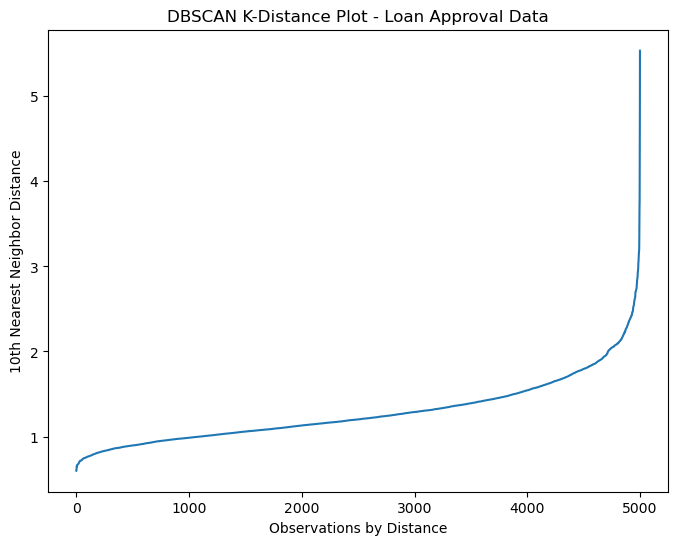

In [42]:
# Generate the k-distance plot
min_samples = 10
neighbors = NearestNeighbors(n_neighbors = min_samples)
neighbors.fit(X_dbscan)
distances, indices = neighbors.kneighbors(X_dbscan)
k_distances = np.sort(distances[:, -1])

# plot
plt.figure(figsize = (8, 6))
plt.plot(k_distances)
plt.xlabel("Observations by Distance")
plt.ylabel("10th Nearest Neighbor Distance")
plt.title("DBSCAN K-Distance Plot - Loan Approval Data")
plt.show()

##### Initial DBSCAN Model

In [43]:
dbscan_1 = DBSCAN(eps = 2.0, min_samples = 10)
dbscan_labels = dbscan_1.fit_predict(X_dbscan)

dbscan_results = X_dbscan.copy()
dbscan_results["Cluster"] = dbscan_labels
dbscan_results["loan_status"] = y_dbscan.loc[X_dbscan.index]

dbscan_cluster_distribution_1 = dbscan_results["Cluster"].value_counts().sort_index()
print("DBSCAN Cluster Distribution:\n", dbscan_cluster_distribution_1)

n_clusters = len(set(dbscan_labels) - {-1})
n_noise = np.sum(dbscan_labels == -1)
noise_percent = n_noise / len(dbscan_labels) * 100

print("\nNumber of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)
print("Noise Percentage:", noise_percent,"%")

DBSCAN Cluster Distribution:
 Cluster
-1      72
 0    4928
Name: count, dtype: int64

Number of Clusters: 1
Number of Noise Points: 72
Noise Percentage: 1.44 %


In [44]:
# Examine rates by cluster
cluster_summary = dbscan_results.groupby("Cluster").agg(
    Borrowers = ("loan_status", "count"),
    Approved = ("loan_status", "sum"),
    Approval_Rate = ("loan_status", "mean")
)

cluster_summary["Approval_Rate"] *= 100
display(cluster_summary.round(4))

,Borrowers,Approved,Approval_Rate
Cluster,,,
-1,72,40,55.5556
0,4928,2692,54.6266


##### DBSCAN Parameter Tuning

In [45]:
eps_values = [1.0, 1.25, 1.5, 1.75, 2.0, 2.25]
min_samples_values = [5, 10, 15]

dbscan_tuning = []

for eps in eps_values:
    for min_samples in min_samples_values:

        model = DBSCAN(eps = eps, min_samples = min_samples)
        labels = model.fit_predict(X_dbscan)

        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(labels == -1)
        noise_mask = labels == -1

        noise_approval_rate = (
            y_dbscan.to_numpy()[noise_mask].mean() * 100
            if n_noise > 0 else np.nan
        )

        dbscan_tuning.append({
            "eps": eps,
            "min_samples": min_samples,
            "Clusters": n_clusters,
            "Noise": n_noise,
            "Noise %": n_noise  / len(labels) * 100,
            "Noise Approval Rate %": noise_approval_rate
        })

dbscan_tuning_df = pd.DataFrame(dbscan_tuning)
display(dbscan_tuning_df.round(4))


,eps,min_samples,Clusters,Noise,Noise %,Noise Approval Rate %
0,1.00,5,31,1878,37.56,55.3781
1,1.00,10,10,2840,56.80,55.4930
2,1.00,15,4,3594,71.88,54.4240
3,1.25,5,5,733,14.66,55.7981
4,1.25,10,3,1175,23.50,56.2553
5,1.25,15,2,1581,31.62,55.0917
6,1.50,5,6,290,5.80,53.1034
7,1.50,10,1,495,9.90,53.7374
8,1.50,15,1,659,13.18,54.3247
9,1.75,5,2,92,1.84,51.0870


##### Examine selected model

In [46]:
dbscan_2 = DBSCAN(eps = 1.5, min_samples = 5)
dbscan_labels_2 = dbscan_2.fit_predict(X_dbscan)

dbscan_results_2 = X_dbscan.copy()
dbscan_results_2["Cluster"] = dbscan_labels_2
dbscan_results_2["loan_status"] = y_dbscan.loc[X_dbscan.index]

dbscan_cluster_distribution_2 = dbscan_results_2["Cluster"].value_counts().sort_index()
print("DBSCAN Cluster Distribution:\n", dbscan_cluster_distribution_2)

n_clusters = len(set(dbscan_labels_2) - {-1})
n_noise = np.sum(dbscan_labels_2 == -1)
noise_percent = n_noise / len(dbscan_labels_2) * 100

print("\nNumber of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)
print("Noise Percentage:", round(noise_percent, 4), "%")

# Examine rates by cluster
cluster_summary_2 = dbscan_results_2.groupby("Cluster").agg(
    Borrowers = ("loan_status", "count"),
    Approved = ("loan_status", "sum"),
    Approval_Rate = ("loan_status", "mean")
)

cluster_summary_2["Approval_Rate"] *= 100
display(cluster_summary_2.round(4))

## Silhouette Score
mask = dbscan_labels_2 != -1

if len(np.unique(dbscan_labels_2[mask])) >= 2:
    score = silhouette_score(
        X_dbscan.loc[mask],
        dbscan_labels_2[mask]
    )

    print("DBSCAN Silhouette Score:", round(score, 4))
else:
    print("Silhouette Score can't be calculated")

DBSCAN Cluster Distribution:
 Cluster
-1     290
 0    4692
 1       3
 2       3
 3       3
 4       4
 5       5
Name: count, dtype: int64

Number of Clusters: 6
Number of Noise Points: 290
Noise Percentage: 5.8 %


,Borrowers,Approved,Approval_Rate
Cluster,,,
-1,290,154,53.1034
0,4692,2566,54.6888
1,3,3,100.0000
2,3,3,100.0000
3,3,3,100.0000
4,4,0,0.0000
5,5,3,60.0000


DBSCAN Silhouette Score: 0.1118


##### Final Model

In [47]:
final_labels = dbscan_labels_2
n_clusters = len(set(final_labels) - {-1})
n_noise = np.sum(final_labels == -1)
mask = final_labels != -1

print("Final DBSCAN Evaluation")
print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)
print("Noise Percentage:", round(n_noise / len(final_labels) * 100, 4), "%")

if len(np.unique(final_labels[mask])) >= 2:
    final_silhouette = silhouette_score(
        X_dbscan.loc[mask],
        final_labels[mask]
    )

    print("Silhouette Score:", round(final_silhouette, 4))
else:
    print("Silhouette Score N/A")

display(cluster_summary_2.round(4))

Final DBSCAN Evaluation
Number of Clusters: 6
Number of Noise Points: 290
Noise Percentage: 5.8 %
Silhouette Score: 0.1118


,Borrowers,Approved,Approval_Rate
Cluster,,,
-1,290,154,53.1034
0,4692,2566,54.6888
1,3,3,100.0000
2,3,3,100.0000
3,3,3,100.0000
4,4,0,0.0000
5,5,3,60.0000


### HAC

In [48]:
X_hac  = X_dbscan.sample(n = 1000, random_state = 42).copy()
y_hac = y_dbscan.loc[X_hac.index].copy()

print("HAC Data Shape:", X_hac.shape)
print("\nLoan Approval Distribution:")
print(y_hac.value_counts())
print("\nLoan Approval Rate:")
print(y_hac.value_counts(normalize = True))


HAC Data Shape: (1000, 10)

Loan Approval Distribution:
loan_status
1    535
0    465
Name: count, dtype: int64

Loan Approval Rate:
loan_status
1    0.535
0    0.465
Name: proportion, dtype: float64


Dendrogram

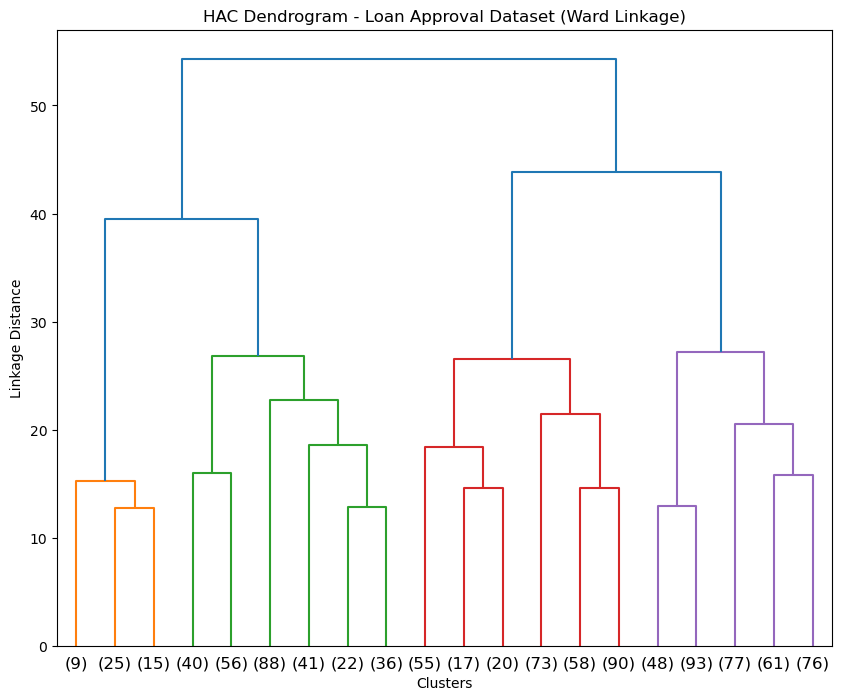

In [49]:
linked = linkage(X_hac, method = "ward")
plt.figure(figsize = (10, 8))

dendrogram(
    linked,
    truncate_mode = "lastp",
    p = 20,
    show_leaf_counts = True
)

plt.title("HAC Dendrogram - Loan Approval Dataset (Ward Linkage)")
plt.xlabel("Clusters")
plt.ylabel("Linkage Distance")
plt.show()

In [50]:
## Fit HAC Model

hac_1 = AgglomerativeClustering(n_clusters = 4, linkage = "ward")

hac_labels = hac_1.fit_predict(X_hac)

hac_results = X_hac.copy()
hac_results["Cluster"] = hac_labels
hac_results["loan_status"] = y_hac.loc[X_hac.index]

print("HAC Cluster Distribution:")
print(hac_results["Cluster"].value_counts().sort_index())

## Silhouette Score
hac_silhouette = silhouette_score(X_hac, hac_labels)
print("\nHAC Silhouette Score:", round(hac_silhouette, 4))

HAC Cluster Distribution:
Cluster
0    355
1    283
2    313
3     49
Name: count, dtype: int64

HAC Silhouette Score: 0.1347


In [51]:
# Exmapine approal rates by cluster
cluster_summary = hac_results.groupby("Cluster").agg(
    Borrowers = ("loan_status", "count"),
    Approved = ("loan_status", "sum"),
    Approval_Rate = ("loan_status", "mean")
)

cluster_summary["Approval_Rate"] *= 100
display(cluster_summary.round(4))

,Borrowers,Approved,Approval_Rate
Cluster,,,
0,355,120,33.8028
1,283,133,46.9965
2,313,260,83.0671
3,49,22,44.8980


In [52]:
## HAC Linkage Comparison
linkage_methods = ["ward", "complete", "average", "single"]
hac_comparison = []

for method in linkage_methods:

    hac_model = AgglomerativeClustering(n_clusters= 4, linkage = method)
    labels = hac_model.fit_predict(X_hac)
    score = silhouette_score(X_hac, labels)
    cluster_sizes = pd.Series(labels).value_counts()

    hac_comparison.append({
        "Linkage": method,
        "Clusters": len(np.unique(labels)),
        "Silhouette Score": score,
        "Smallest Cluster": cluster_sizes.min(),
        "Largest Cluster": cluster_sizes.max()
    })
hac_comparison_df = pd.DataFrame(hac_comparison)
display(hac_comparison_df.round(4))

,Linkage,Clusters,Silhouette Score,Smallest Cluster,Largest Cluster
0,ward,4,0.1347,49,355
1,complete,4,0.1897,7,691
2,average,4,0.1900,1,925
3,single,4,0.3994,1,997


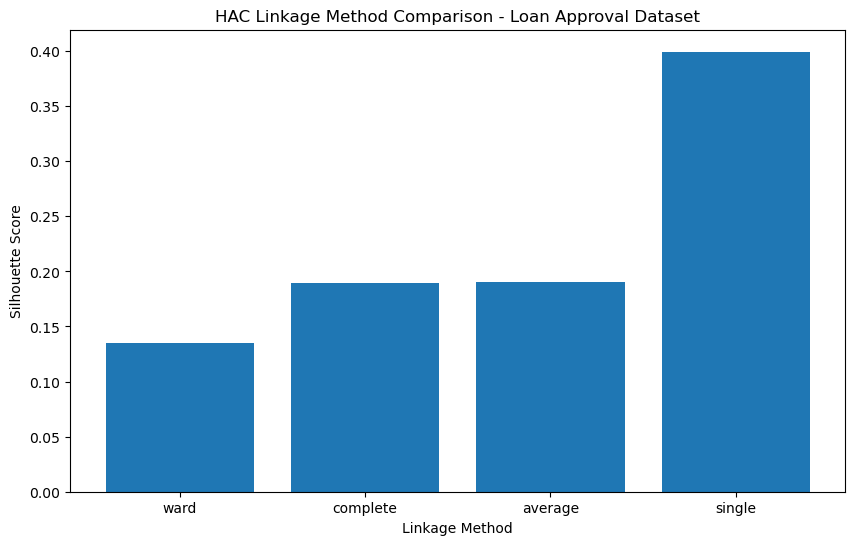

In [53]:
# Graph it
plt.figure(figsize = (10, 6))
plt.bar(
    hac_comparison_df["Linkage"],
    hac_comparison_df["Silhouette Score"]
)

plt.xlabel("Linkage Method")
plt.ylabel("Silhouette Score")
plt.title("HAC Linkage Method Comparison - Loan Approval Dataset")
plt.show()

In [54]:
## Test different HAC Clusters

hac_k_results = []

for k in range(2, 11):

  model = AgglomerativeClustering(
      n_clusters = k,
      linkage = "ward"
  )

  labels = model.fit_predict(X_hac)
  score = silhouette_score(X_hac, labels)
  sizes = pd.Series(labels).value_counts()

  hac_k_results.append({
      "Clusters": k,
      "Silhouette Score": score,
      "Smallest Cluster": sizes.min(),
      "Largest Cluster": sizes.max()
  })

hac_k_df = pd.DataFrame(hac_k_results)

display(hac_k_df.round(4))

,Clusters,Silhouette Score,Smallest Cluster,Largest Cluster
0,2,0.1778,332,668
1,3,0.1170,313,355
2,4,0.1347,49,355
3,5,0.0940,49,313
4,6,0.0907,49,313
5,7,0.0968,49,221
6,8,0.0988,49,221
7,9,0.0894,49,214
8,10,0.0878,49,148


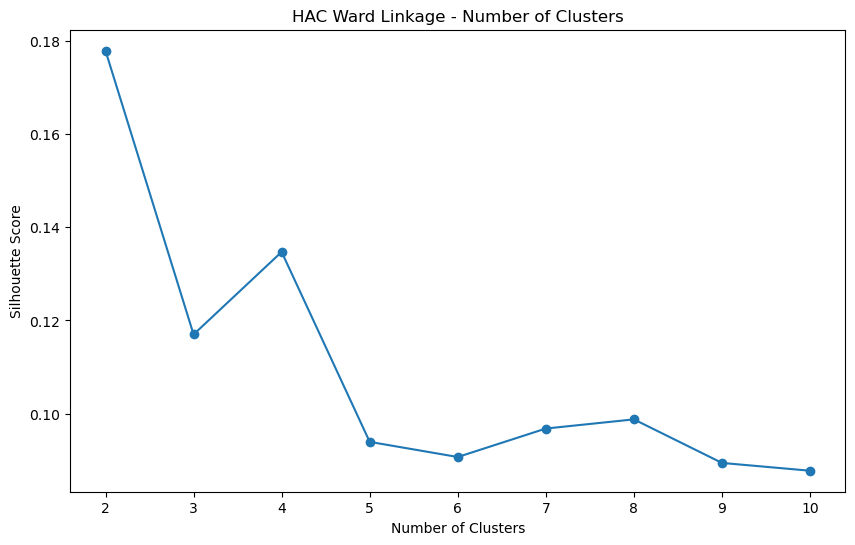

In [55]:
# visualzie it
plt.figure(figsize = (10, 6))
plt.plot(
    hac_k_df["Clusters"],
    hac_k_df["Silhouette Score"],
    marker = "o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("HAC Ward Linkage - Number of Clusters")
plt.show()

In [56]:
## fit final model

hac_final = AgglomerativeClustering(n_clusters = 2, linkage = "ward")

hac_final_labels = hac_final.fit_predict(X_hac)

hac_final_results = X_hac.copy()
hac_final_results["Cluster"] = hac_final_labels
hac_final_results["loan_status"] = y_hac.loc[X_hac.index]

print("HAC Cluster Distribution:")
print(hac_final_results["Cluster"].value_counts().sort_index())

## Silhouette Score
hac_final_silhouette = silhouette_score(X_hac, hac_final_labels)
print("\nHAC Silhouette Score:", round(hac_final_silhouette, 4))

HAC Cluster Distribution:
Cluster
0    668
1    332
Name: count, dtype: int64

HAC Silhouette Score: 0.1778


In [57]:
## Final HAC Eval ##

hac_final_silhouette = silhouette_score(X_hac, hac_final_labels)

hac_final_summary = hac_final_results.groupby("Cluster").agg(
    Borrowers = ("loan_status", "count"),
    Approved = ("loan_status", "sum"),
    Approval_Rate = ("loan_status", "mean")
)
hac_final_summary["Approval_Rate"] *= 100

print("Final HAC Eval")
print("Silhouette Score:", round(hac_final_silhouette, 4))
print("Number of Clusters:", len(np.unique(hac_final_labels)))

display(hac_final_summary.round(4))

Final HAC Eval
Silhouette Score: 0.1778
Number of Clusters: 2


,Borrowers,Approved,Approval_Rate
Cluster,,,
0,668,380,56.8862
1,332,155,46.6867
